219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.
95/95 ━━━━━━━━━━━━━━━━━━━━ 344s 3s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 48s 6s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       116
           1       0.75      0.91      0.82        44
           2       1.00      0.80      0.89        40
           3       0.89      0.84      0.86        80

    accuracy                           0.91       280
   macro avg       0.90      0.89      0.89       280
weighted avg       0.92      0.91      0.91       280



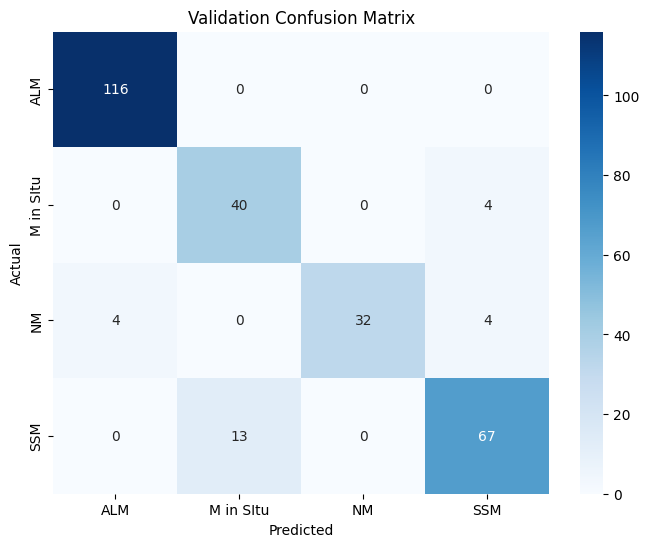

Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       1.00      0.83      0.91        24
           2       0.90      1.00      0.95        18
           3       0.91      1.00      0.95        20

    accuracy                           0.95        88
   macro avg       0.95      0.96      0.95        88
weighted avg       0.96      0.95      0.95        88



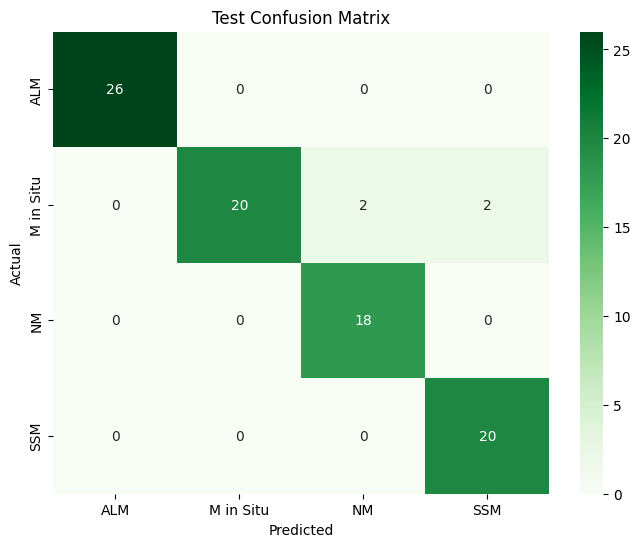

SVM model saved to svm_InceptionResNetV2_SAVE_model.joblib
Predictions saved to test_predictions_svm_InceptionResNetV2.csv
Model loaded from /kaggle/working/svm_InceptionResNetV2_SAVE_model.joblib
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 25s 6s/step 
Predictions, True Labels, and Confidence Scores:
                                    Image  True Label  Prediction  Confidence
0               ALM/d132642d-IMG_2864.JPG           0           0    0.989451
1               ALM/d1805016-IMG_1912.JPG           0           0    0.996432
2               ALM/d27694e9-IMG_2746.JPG           0           0    0.963916
3               ALM/d55466c0-IMG_2954.JPG           0           0    0.992260
4               ALM/d7060567-IMG_1911.JPG           0           0    0.996014
..                                    ...         ...         ...         ...
83  SSM/e2e461f8-ISIC_0023290_flipped.JPG           3           3    0.998294
84              SSM/e55f3358-IMG_2128.JPG           3           3    0.899505
85      SSM/e55f3358-IMG_2128_flipped.JPG           3           3    0.886932
86          SSM/e9a09f6b-ISIC_0023277.JPG           3           3    0.973336
87  SSM/e9a09f6b-ISIC_0023277_flipped.JPG           3  

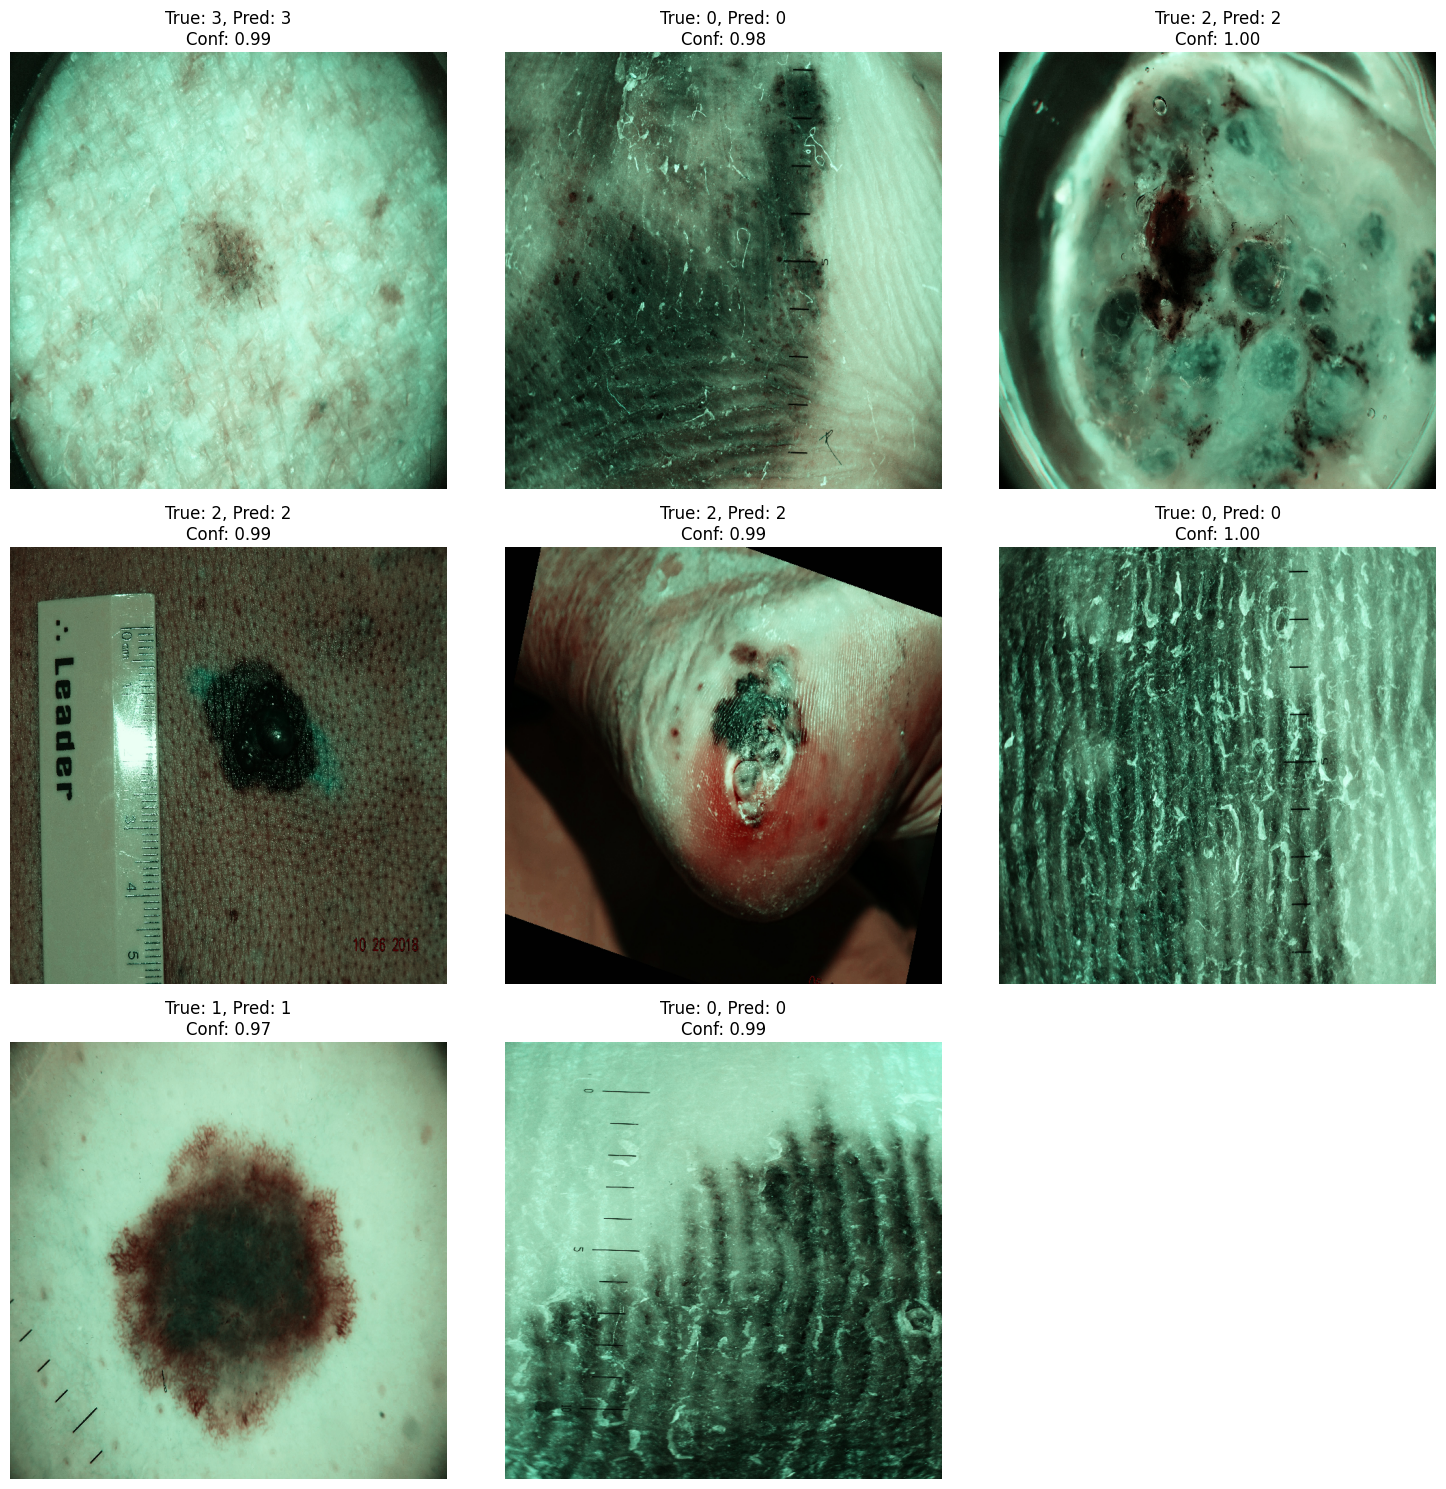

In [7]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-save'
val_dir = '/kaggle/input/valid-save'
test_dir = '/kaggle/input/test-save'


model_path = 'svm_InceptionResNetV2_SAVE_model.joblib'


base_model = tf.keras.applications.InceptionResNetV2(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)


train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary', 
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


svm_model = SVC(probability=True)  
svm_model.fit(train_features, train_labels)


val_predictions = svm_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = svm_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


joblib.dump(svm_model, model_path)
print(f"SVM model saved to {model_path}")


pred_proba = svm_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})


predictions_df.to_csv("test_predictions_svm_InceptionResNetV2.csv", index=False)
print("Predictions saved to test_predictions_svm_InceptionResNetV2.csv")


model_path = '/kaggle/working/svm_InceptionResNetV2_SAVE_model.joblib'
svm_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")


test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


base_model = tf.keras.applications.InceptionResNetV2(weights='imagenet', include_top=False, pooling='avg')


test_features = extract_features(test_generator)[0]


test_predictions = svm_model.predict(test_features)
pred_proba = svm_model.predict_proba(test_features)


predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'True Label': test_generator.classes,  
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})


print("Predictions, True Labels, and Confidence Scores:")
print(predictions_df[['Image', 'True Label', 'Prediction', 'Confidence']])


num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(640, 640))
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0  
    
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Prediction']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()


Found 3028 images belonging to 4 classes.
Found 280 images belonging to 4 classes.
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


95/95 ━━━━━━━━━━━━━━━━━━━━ 233s 2s/step
9/9 ━━━━━━━━━━━━━━━━━━━━ 26s 3s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step
Validation Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       116
           1       0.82      0.91      0.86        44
           2       1.00      0.80      0.89        40
           3       0.91      0.89      0.90        80

    accuracy                           0.93       280
   macro avg       0.92      0.90      0.91       280
weighted avg       0.93      0.93      0.92       280



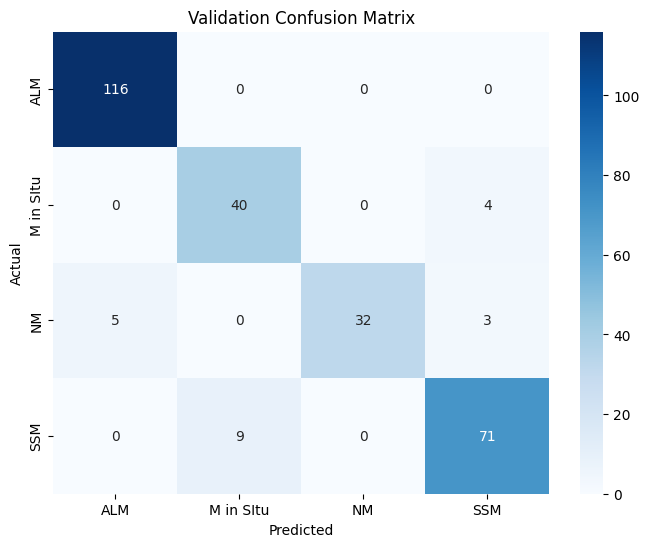

Test Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        26
           1       1.00      0.71      0.83        24
           2       0.95      1.00      0.97        18
           3       0.77      1.00      0.87        20

    accuracy                           0.92        88
   macro avg       0.93      0.93      0.92        88
weighted avg       0.94      0.92      0.92        88



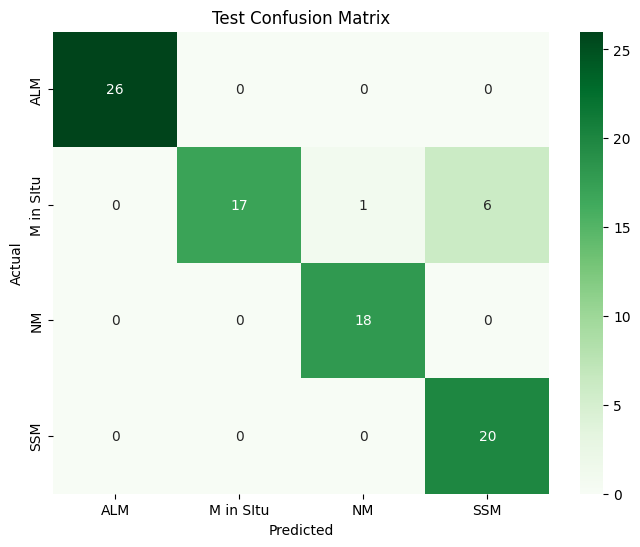

SVM model saved to svm_InceptionResNetV2_RGB_model.joblib
Predictions saved to test_predictions_svm_InceptionResNetV2.csv
Model loaded from /kaggle/working/svm_InceptionResNetV2_RGB_model.joblib
Found 88 images belonging to 4 classes.


/opt/conda/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


3/3 ━━━━━━━━━━━━━━━━━━━━ 26s 6s/step 
Predictions, True Labels, and Confidence Scores:
                                    Image  True Label  Prediction  Confidence
0               ALM/d132642d-IMG_2864.JPG           0           0    0.998197
1               ALM/d1805016-IMG_1912.JPG           0           0    0.994636
2               ALM/d27694e9-IMG_2746.JPG           0           0    0.975424
3               ALM/d55466c0-IMG_2954.JPG           0           0    0.995210
4               ALM/d7060567-IMG_1911.JPG           0           0    0.997320
..                                    ...         ...         ...         ...
83  SSM/e2e461f8-ISIC_0023290_flipped.JPG           3           3    0.997830
84              SSM/e55f3358-IMG_2128.JPG           3           3    0.761015
85      SSM/e55f3358-IMG_2128_flipped.JPG           3           3    0.695274
86          SSM/e9a09f6b-ISIC_0023277.JPG           3           3    0.916302
87  SSM/e9a09f6b-ISIC_0023277_flipped.JPG           3  

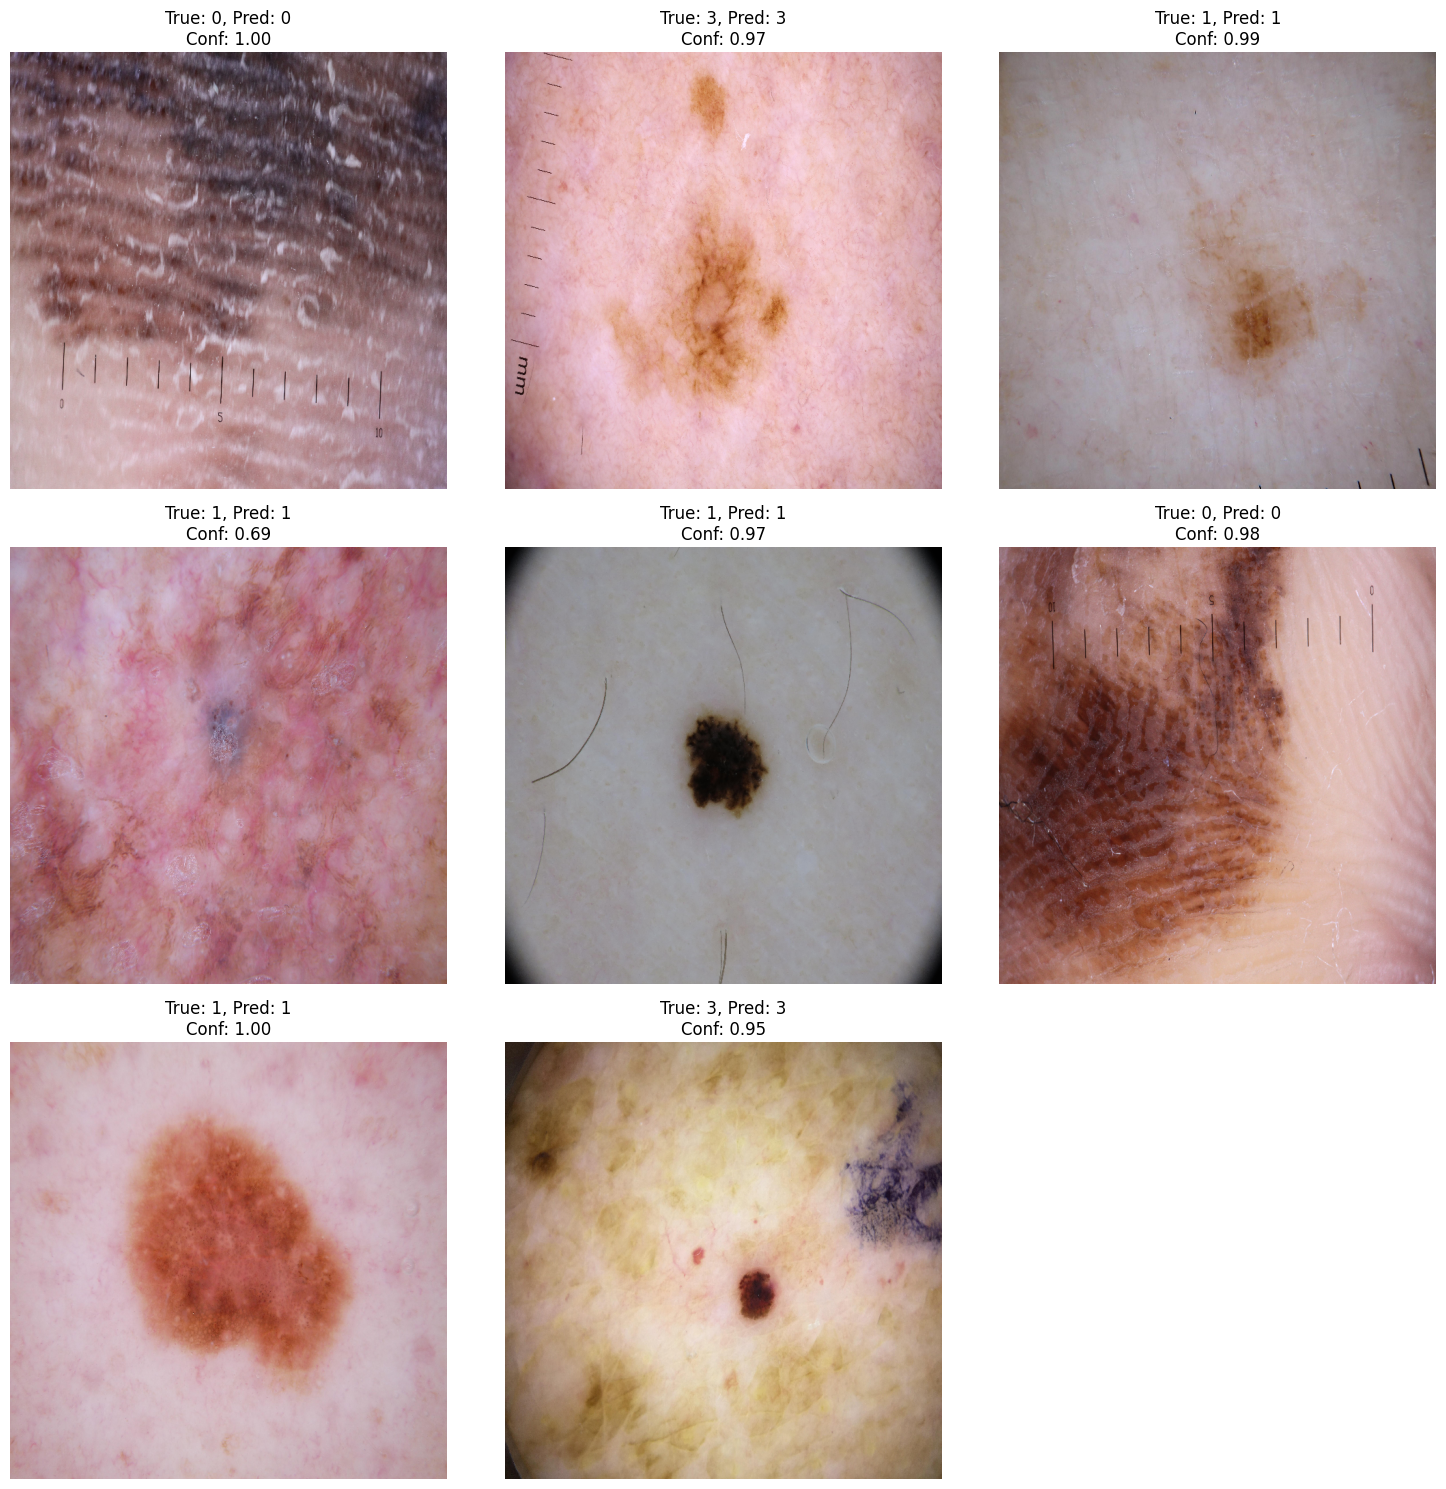

In [8]:
import numpy as np
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import pandas as pd


train_dir = '/kaggle/input/train-rgb'
val_dir = '/kaggle/input/valid-rgb'
test_dir = '/kaggle/input/test-rgb'


model_path = 'svm_InceptionResNetV2_RGB_model.joblib'


base_model = tf.keras.applications.InceptionResNetV2(weights='imagenet', include_top=False, pooling='avg')

datagen = ImageDataGenerator(rescale=1./255)


train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary', 
    shuffle=False
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(640, 640), 
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),  
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

def extract_features(generator):
    features = base_model.predict(generator)
    labels = generator.classes
    return features, labels


train_features, train_labels = extract_features(train_generator)
val_features, val_labels = extract_features(val_generator)
test_features, test_labels = extract_features(test_generator)


svm_model = SVC(probability=True) 
svm_model.fit(train_features, train_labels)


val_predictions = svm_model.predict(val_features)
print("Validation Classification Report:")
print(classification_report(val_labels, val_predictions))

val_cm = confusion_matrix(val_labels, val_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(val_cm, annot=True, fmt="d", cmap="Blues", xticklabels=train_generator.class_indices.keys(), yticklabels=train_generator.class_indices.keys())
plt.title("Validation Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


test_predictions = svm_model.predict(test_features)
print("Test Classification Report:")
print(classification_report(test_labels, test_predictions))


test_cm = confusion_matrix(test_labels, test_predictions)
plt.figure(figsize=(8, 6))
sns.heatmap(test_cm, annot=True, fmt="d", cmap="Greens", xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.title("Test Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()


joblib.dump(svm_model, model_path)
print(f"SVM model saved to {model_path}")


pred_proba = svm_model.predict_proba(test_features)
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})


predictions_df.to_csv("test_predictions_svm_InceptionResNetV2.csv", index=False)
print("Predictions saved to test_predictions_svm_InceptionResNetV2.csv")


model_path = '/kaggle/working/svm_InceptionResNetV2_RGB_model.joblib'
svm_model = joblib.load(model_path)
print(f"Model loaded from {model_path}")


test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(640, 640),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

# Extract test features using InceptionResNetV2
base_model = tf.keras.applications.InceptionResNetV2(weights='imagenet', include_top=False, pooling='avg')

# Extract features from the test set
test_features = extract_features(test_generator)[0]

# Predict using the loaded SVM model
test_predictions = svm_model.predict(test_features)
pred_proba = svm_model.predict_proba(test_features)

# Prepare a DataFrame with true labels, predictions, and confidence scores
predictions_df = pd.DataFrame({
    'Image': test_generator.filenames,
    'True Label': test_generator.classes,  # True labels from the test_generator
    'Prediction': test_predictions,
    'Confidence': [max(proba) for proba in pred_proba]
})

# Print the predictions, true labels, and their confidence values
print("Predictions, True Labels, and Confidence Scores:")
print(predictions_df[['Image', 'True Label', 'Prediction', 'Confidence']])

# Display random images with their true labels, predictions, and confidence
num_images = 8
indices = np.random.choice(len(predictions_df), num_images, replace=False)

plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices):
    img_path = os.path.join(test_dir, predictions_df.loc[idx, 'Image'])
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(640, 640))
    img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0  # Scale the image for display
    
    true_label = predictions_df.loc[idx, 'True Label']
    predicted_label = predictions_df.loc[idx, 'Prediction']
    confidence = predictions_df.loc[idx, 'Confidence']

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_array)
    plt.axis('off')
    plt.title(f"True: {true_label}, Pred: {predicted_label}\nConf: {confidence:.2f}")

plt.tight_layout()
plt.show()
